# E-commerce Analytics | SQL + Python

## Цель проекта

Исследовать данные интернет-магазина за 2021–2025 годы, выявить закономерности в продажах, оценить поведение клиентов и определить наиболее прибыльные товарные категории.

## Инструменты

- PostgreSQL — извлечение, проверка и агрегация данных.
- SQL — анализ продаж, когортный анализ и ABC-классификация.
- Python и pandas — обработка результатов SQL-запросов.
- Matplotlib и Seaborn — визуализация результатов.

## Основные вопросы исследования

1. Как меняется количество заказов со временем?
2. Есть ли сезонность в продажах?
3. Как часто клиенты возвращаются за повторными покупками?
4. Какие категории приносят наибольшую прибыль?
5. Выполняется ли принцип Парето 80/20 для товарного ассортимента?

## Ограничения

Анализ денежных показателей проводится по заказам в USD. В исходных данных обнаружены расхождения между суммами заказов и товарных позиций, поэтому финансовые выводы требуют дополнительной проверки.

In [42]:
import pandas as pd
from sqlalchemy import create_engine, text
from getpass import getpass

db_user = input("Имя пользователя PostgreSQL:")
db_password = getpass("Пароль PostgreSQL:")

engine = create_engine(
    "postgresql+psycopg2://",
    connect_args={
        "host": "localhost",
        "port": 5432,
        "dbname": "ecommerce_analytics",
        "user": db_user,
        "password": db_password,
    }
)

with engine.connect() as conn:
    result = conn.execute(text("SELECT 1"))
    print("Подключение успешно:", result.scalar())

Имя пользователя PostgreSQL: postgres
Пароль PostgreSQL: ········


Подключение успешно: 1


In [43]:
query = """
SELECT
    DATE_TRUNC('month', order_date::date)::date AS month,
    COUNT(DISTINCT order_id) AS orders_count
FROM raw.orders
GROUP BY 1
ORDER BY 1;
"""

df_monthly = pd.read_sql_query(query, engine)

df_monthly["month"] = pd.to_datetime(df_monthly["month"])

df_monthly.head(10)

,month,orders_count
0,2021-01-01,1906
1,2021-02-01,1565
2,2021-03-01,2166
3,2021-04-01,1943
4,2021-05-01,2096
5,2021-06-01,2203
6,2021-07-01,2036
7,2021-08-01,2474
8,2021-09-01,2134
9,2021-10-01,2324


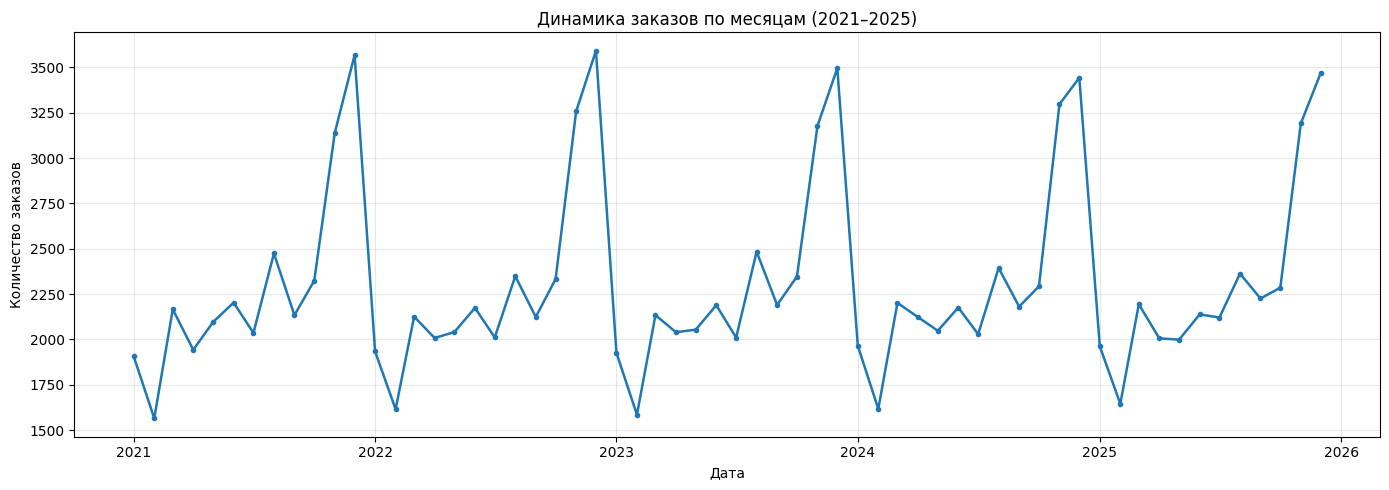

In [44]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))

plt.plot(
    df_monthly["month"],
    df_monthly["orders_count"],
    marker="o",
    markersize=3,
    linewidth=1.8
)

plt.title("Динамика заказов по месяцам (2021–2025)")
plt.xlabel("Дата")
plt.ylabel("Количество заказов")

plt.grid(alpha=0.3)
plt.tight_layout()
from pathlib import Path

Path("images").mkdir(exist_ok=True)

plt.savefig(
    "images/sales_dynamics.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

### Вывод: динамика количества заказов

За период 2021–2025 годов количество заказов не демонстрирует устойчивого ежегодного роста. При этом наблюдаются регулярные сезонные колебания.

Наиболее заметное увеличение количества заказов происходит в ноябре и декабре. В феврале, напротив, наблюдаются более низкие показатели.

**Бизнес-интерпретация:** компании стоит учитывать сезонность при планировании товарных запасов, маркетинговых кампаний и нагрузки на персонал.

**Ограничение:** количество заказов не отражает денежный объём продаж. Для анализа выручки необходимо отдельно учитывать валюту заказов.

In [45]:
df_seasonality = df_monthly.copy()

df_seasonality["year"] = df_seasonality["month"].dt.year
df_seasonality["month_num"] = df_seasonality["month"].dt.month

df_seasonality.head()

seasonality_pivot = df_seasonality.pivot(
    index="month_num",
    columns="year",
    values="orders_count"
)

seasonality_pivot

year,2021,2022,2023,2024,2025
month_num,,,,,
1,1906,1934,1926,1965,1962
2,1565,1615,1585,1617,1645
3,2166,2126,2134,2202,2194
4,1943,2008,2040,2123,2006
5,2096,2041,2054,2048,1999
6,2203,2174,2189,2176,2138
7,2036,2011,2010,2029,2121
8,2474,2349,2484,2394,2363
9,2134,2124,2190,2181,2226


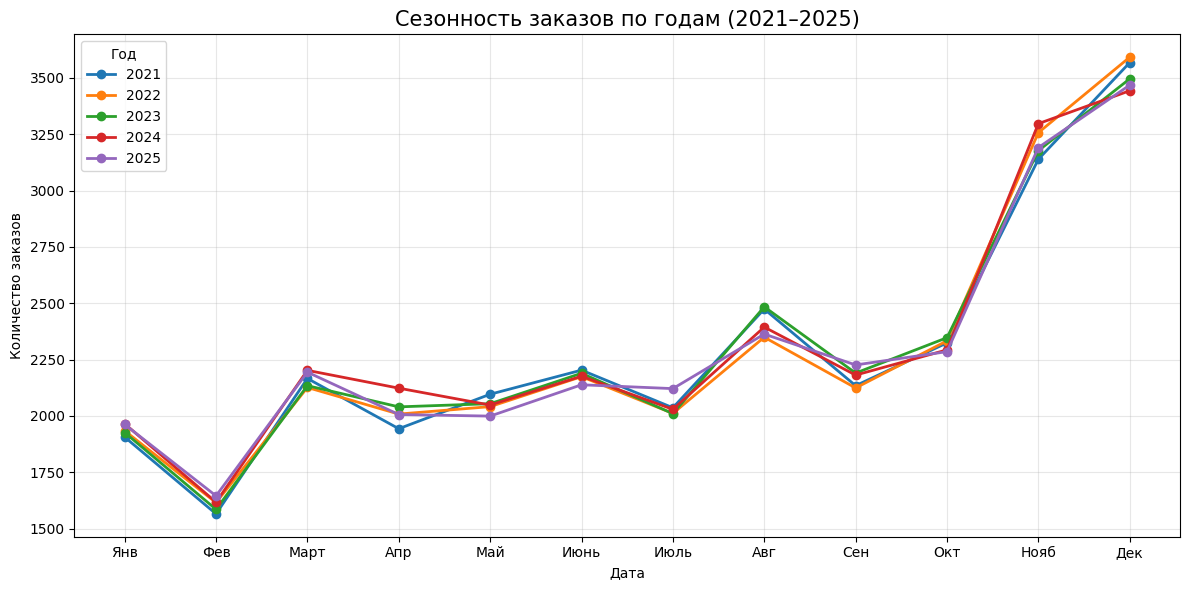

In [66]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

for year in seasonality_pivot.columns:
    plt.plot(
        seasonality_pivot.index,
        seasonality_pivot[year],
        marker="o",
        linewidth=2,
        label=str(year)
    )

plt.title("Сезонность заказов по годам (2021–2025)", fontsize=15)
plt.xlabel("Дата")
plt.ylabel("Количество заказов")

plt.xticks(
    range(1, 13),
    ["Янв", "Фев", "Март", "Апр", "Май", "Июнь",
     "Июль", "Авг", "Сен", "Окт", "Нояб", "Дек"]
)

plt.legend(title="Год")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "images/seasonality.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Вывод: сезонность заказов

Сравнение помесячной динамики за 2021–2025 годы показывает повторяющуюся сезонную закономерность.

В ноябре и декабре количество заказов увеличивается, а в феврале наблюдается снижение. Похожая картина повторяется на протяжении нескольких лет.

**Гипотеза о сезонности подтвердилась:** спрос зависит от времени года, а рост заказов в конце года нельзя автоматически считать признаком долгосрочного роста бизнеса.

**Бизнес-рекомендации:**
- Заранее планировать товарные запасы перед ноябрём и декабрём.
- Учитывать сезонные колебания при прогнозировании продаж.
- Сравнивать показатели не только с предыдущим месяцем (MoM), но и с аналогичным месяцем прошлого года (YoY).

**Ограничение:** график показывает количество заказов, но не объясняет причины сезонных колебаний. Для проверки влияния праздников и маркетинговых акций потребуются дополнительные данные.

In [47]:
query = """
WITH first_orders AS (
    SELECT
        customer_id,
        DATE_TRUNC('month', MIN(order_date::date))::date
            AS cohort_month
    FROM raw.orders
    GROUP BY customer_id
),

customer_activity AS (
    SELECT DISTINCT
        o.customer_id,
        f.cohort_month,
        (
            EXTRACT(YEAR FROM o.order_date::date)::int
            - EXTRACT(YEAR FROM f.cohort_month)::int
        ) * 12
        +
        (
            EXTRACT(MONTH FROM o.order_date::date)::int
            - EXTRACT(MONTH FROM f.cohort_month)::int
        ) AS month_number
    FROM raw.orders o
    JOIN first_orders f
        ON o.customer_id = f.customer_id
),

cohort_counts AS (
    SELECT
        cohort_month,
        month_number,
        COUNT(DISTINCT customer_id) AS active_customers
    FROM customer_activity
    GROUP BY cohort_month, month_number
),

cohort_sizes AS (
    SELECT
        cohort_month,
        COUNT(DISTINCT customer_id) AS cohort_size
    FROM first_orders
    GROUP BY cohort_month
)

SELECT
    c.cohort_month,
    c.month_number,
    ROUND(
        c.active_customers * 100.0
        / NULLIF(s.cohort_size, 0),
        2
    ) AS retention_pct
FROM cohort_counts c
JOIN cohort_sizes s
    ON c.cohort_month = s.cohort_month
WHERE c.month_number BETWEEN 0 AND 6
ORDER BY c.cohort_month, c.month_number;
"""

df_retention = pd.read_sql_query(query, engine)

df_retention.head()

,cohort_month,month_number,retention_pct
0,2021-01-01,0,100.00
1,2021-01-01,1,6.25
2,2021-01-01,2,7.79
3,2021-01-01,3,6.36
4,2021-01-01,4,8.22


In [48]:
df_retention["cohort_month"] = pd.to_datetime(
    df_retention["cohort_month"]
)

retention_matrix = df_retention.pivot(
    index="cohort_month",
    columns="month_number",
    values="retention_pct"
)

retention_matrix.index = retention_matrix.index.strftime("%Y-%m")

retention_matrix.head()

month_number,0,1,2,3,4,5,6
cohort_month,,,,,,,
2021-01,100.0,6.25,7.79,6.36,8.22,8.44,7.79
2021-02,100.0,8.15,7.58,8.43,9.29,8.51,9.72
2021-03,100.0,8.24,6.94,9.22,7.92,9.06,8.73
2021-04,100.0,8.42,8.62,8.82,9.08,9.02,8.88
2021-05,100.0,8.37,7.16,9.66,8.24,8.85,10.40


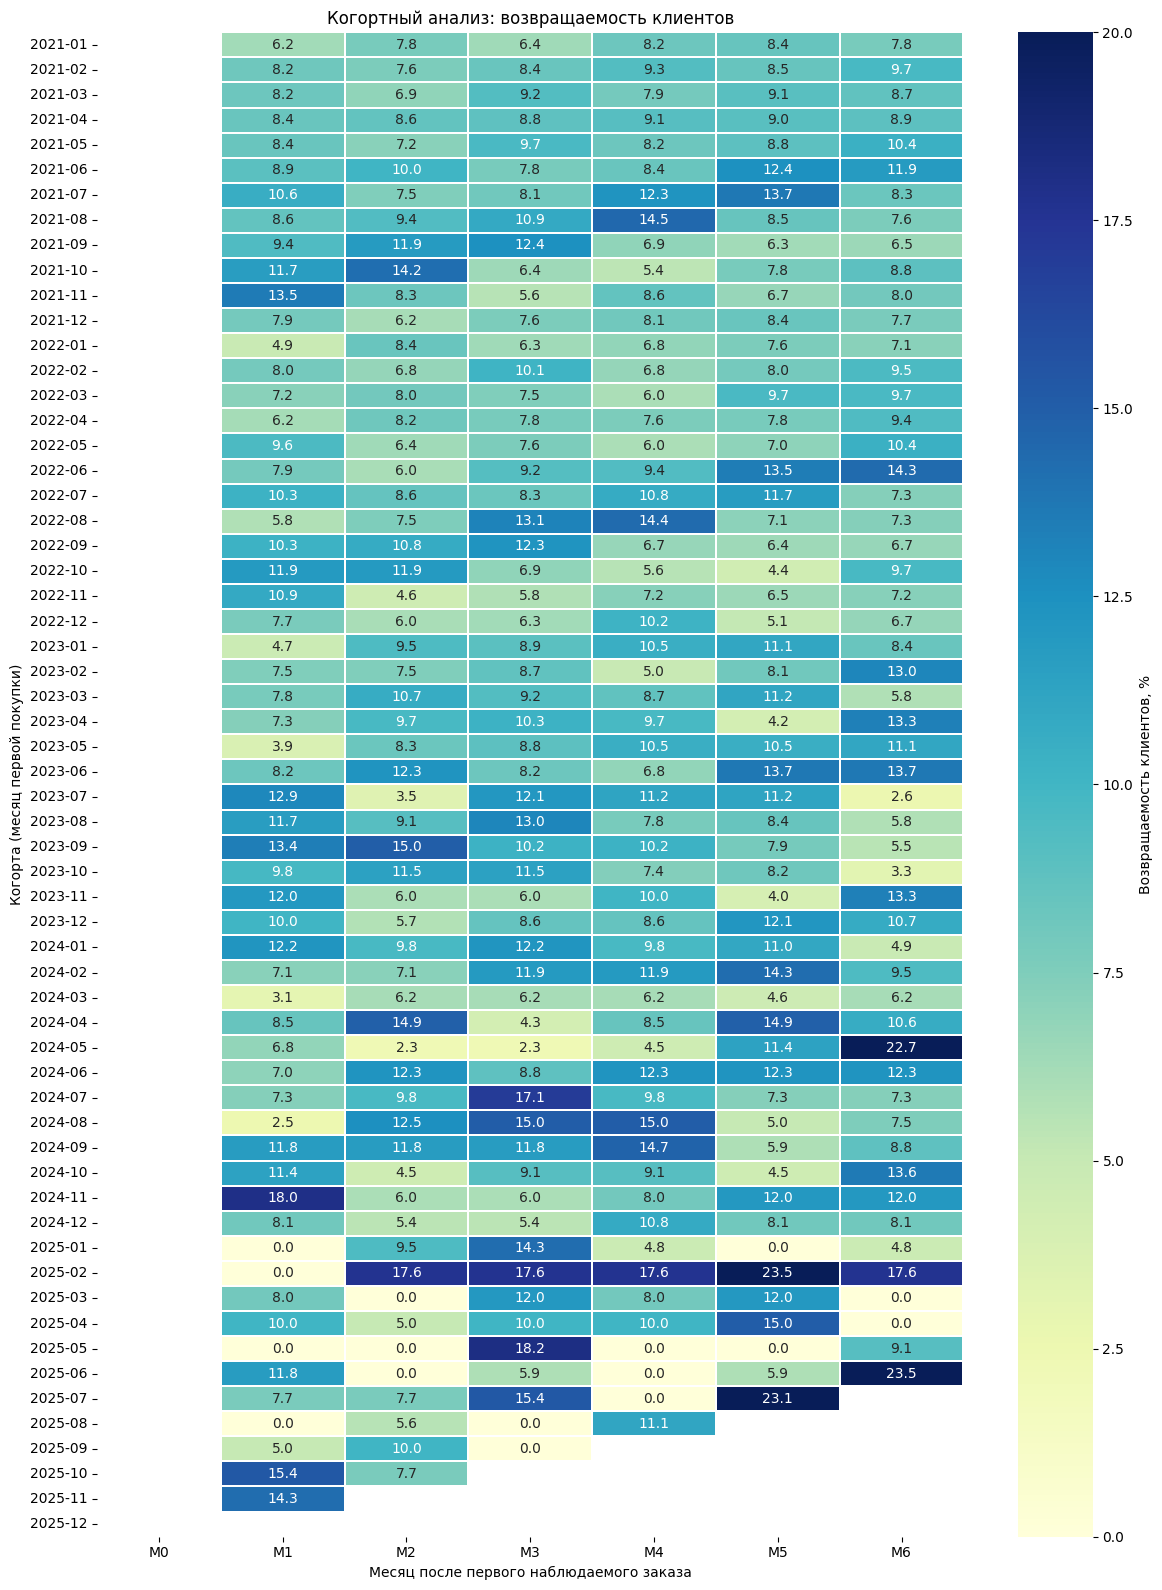

In [65]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path

retention_matrix = df_retention.pivot(
    index="cohort_month",
    columns="month_number",
    values="retention_pct"
)

retention_matrix.index = pd.to_datetime(retention_matrix.index)
retention_matrix = retention_matrix.reindex(columns=range(7))

# Последний месяц наблюдения в исходных данных

query = """
SELECT MAX(order_date::date) AS last_order_date
FROM raw.orders
"""

last_order_date = pd.read_sql_query(query, engine)
last_month = (
    pd.to_datetime(last_order_date["last_order_date"].iloc[0])
    .to_period("M")
    .to_timestamp()
)

# Заполняем нулями только месяцы,
# которые уже наступили в периоде наблюдения
for cohort in retention_matrix.index:
    for month_number in retention_matrix.columns:
        activity_month = cohort + pd.DateOffset(months=int(month_number))

        if activity_month <= last_month:
            if pd.isna(retention_matrix.loc[cohort, month_number]):
                retention_matrix.loc[cohort, month_number] = 0

retention_matrix.index = retention_matrix.index.strftime("%Y-%m")
retention_matrix.columns = [f"M{i}" for i in range(7)]

# Для наглядности показываем цветом только M1-M6
# M0 остаётся в таблице со значением 100%
plot_matrix = retention_matrix.copy()
plot_matrix["M0"] = np.nan

fig, ax = plt.subplots(figsize=(12, 16))

sns.heatmap(
    plot_matrix,
    annot=retention_matrix,
    fmt=".1f",
    cmap="YlGnBu",
    vmin=0,
    vmax=20,
    linewidths=0.3,
    mask=plot_matrix.isna(),
    cbar_kws={"label": "Возвращаемость клиентов, %"},
    ax=ax
)

ax.set_title("Когортный анализ: возвращаемость клиентов")
ax.set_xlabel("Месяц после первого наблюдаемого заказа")
ax.set_ylabel("Когорта (месяц первой покупки)")

plt.tight_layout()

Path("images").mkdir(exist_ok=True)

plt.savefig(
    "images/retention_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Вывод: когортный анализ клиентов

Когортный анализ показал, что относительно небольшая доля клиентов возвращается за покупками в конкретный месяц после первого наблюдаемого заказа.

Например, среди клиентов когорты января 2021 года:
- В первый месяц после первой покупки (M1) вернулись 6,25%.
- Во второй месяц (M2) — 7,79%.
- В третий месяц (M3) — 6,36%.

При этом общий Repeat Purchase Rate за 2021–2025 годы составляет 97,90%.

**Почему показатели различаются?**

Repeat Purchase Rate показывает долю клиентов, совершивших минимум два заказа за весь пятилетний период.

Когортный анализ показывает, какая доля клиентов совершила хотя бы один заказ в конкретном календарном месяце после первого наблюдаемого заказа.

Таким образом, клиент может совершать повторные покупки, но с большими интервалами между ними.

**Бизнес-интерпретация:** высокая доля повторных покупателей не означает, что клиенты возвращаются ежемесячно.

**Рекомендации:**
- Изучить интервалы между покупками.
- Сегментировать клиентов по частоте заказов.
- Проверить гипотезы о повышении частоты повторных покупок.

**Ограничения:** первый заказ определяется только в пределах доступных данных за 2021–2025 годы. Месячная возвращаемость не требует покупок в каждом предыдущем месяце. Для последних когорт часть будущих месяцев ещё недоступна.

In [50]:
query = """
SELECT
    pc.product_category,
    ROUND(SUM(oi.profit::numeric), 2) AS total_profit
FROM raw.product_catalog AS pc
JOIN raw.order_items AS oi
    ON pc.product_id = oi.product_id
JOIN raw.orders AS o
    ON oi.order_id = o.order_id
WHERE o.currency = 'USD'
GROUP BY pc.product_category
ORDER BY total_profit DESC;
"""

df_categories = pd.read_sql_query(query, engine)

df_categories.head()

,product_category,total_profit
0,Electronics,7647363.68
1,Jewelry,5729648.17
2,Home Appliances,5717182.80
3,Sports & Outdoors,3980408.71
4,Automotive,3569933.57


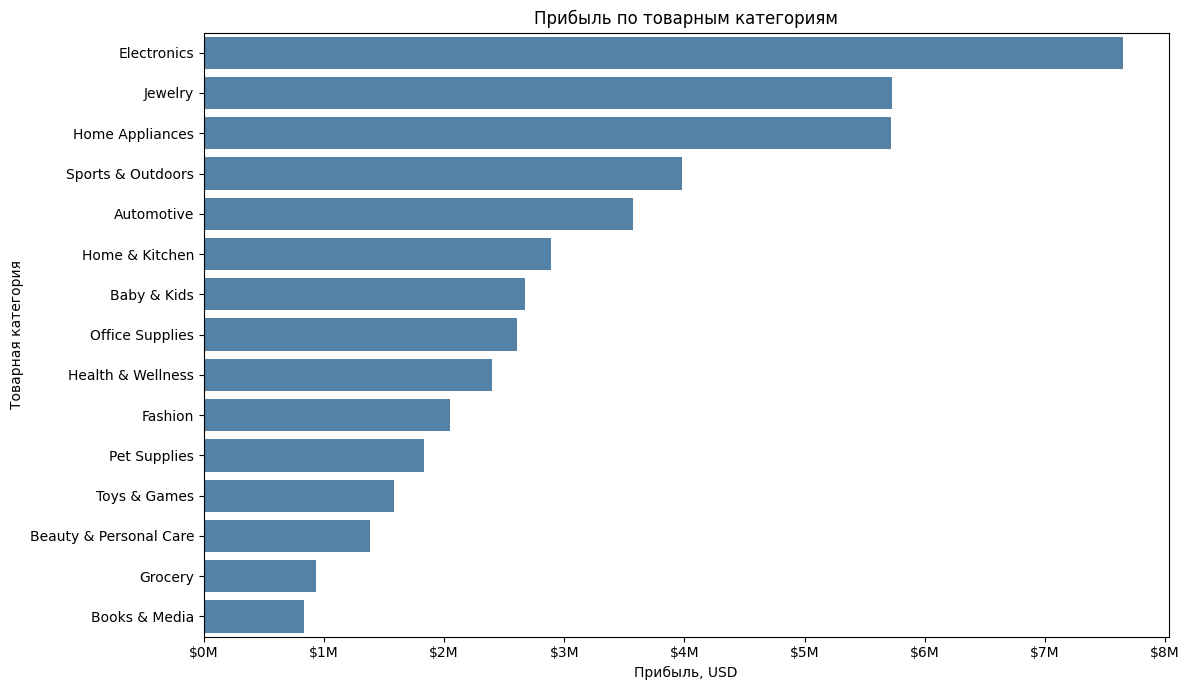

In [60]:
import matplotlib.pyplot as plt
import seaborn as sns

df_categories["total_profit"] = pd.to_numeric(
    df_categories["total_profit"]
)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=df_categories,
    x="total_profit",
    y="product_category",
    color="steelblue"
)

ax = plt.gca()
ax.set_title("Прибыль по товарным категориям")
ax.set_xlabel("Прибыль, USD")
ax.set_ylabel("Товарная категория")

from matplotlib.ticker import FuncFormatter

ax.xaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f"${x / 1_000_000:.0f}M")
)

plt.tight_layout()

plt.savefig(
    "images/category_profit.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Вывод: прибыльность товарных категорий

Анализ показал, что прибыль распределена между товарными категориями неравномерно.

Наибольшую суммарную прибыль приносят:

1. **Electronics** — 7,65 млн USD.
2. **Jewelry** — 5,73 млн USD.
3. **Home Appliances** — 5,72 млн USD.

Совокупно эти три категории формируют около **41,65% общей прибыли** в анализируемой выборке USD.

При этом высокая абсолютная прибыль не всегда означает высокую рентабельность.

Например, категория Electronics лидирует по суммарной прибыли, но её маржинальность составляет около 32,22%. Категория Grocery имеет более высокую маржинальность — 53,73%, однако приносит значительно меньшую абсолютную прибыль.

**Бизнес-интерпретация:** при оценке эффективности товарных категорий важно учитывать не только общую прибыль, но и маржинальность, объём продаж и прибыль на единицу товара.

**Рекомендации:**
- Поддерживать доступность товаров из наиболее прибыльных категорий.
- Исследовать возможности повышения маржинальности Electronics.
- Оценить потенциал роста продаж категорий с высокой маржинальностью.
- При принятии решений учитывать спрос, затраты и оборачиваемость товаров.

**Ограничения:** денежные показатели рассчитаны только по заказам в USD. В исходных данных обнаружены расхождения между суммами заказов и товарных позиций, поэтому финансовые результаты требуют дополнительной сверки.

In [68]:
query = """
WITH product_metrics AS (
    SELECT
        pc.product_id,
        SUM(oi.profit::numeric) AS total_profit
    FROM raw.product_catalog pc
    JOIN raw.order_items oi
        ON pc.product_id = oi.product_id
    JOIN raw.orders o
        ON oi.order_id = o.order_id
    WHERE o.currency = 'USD'
    GROUP BY pc.product_id
),

product_abc AS (
    SELECT
        product_id,
        total_profit,

        SUM(total_profit) OVER (
            ORDER BY total_profit DESC, product_id
            ROWS BETWEEN UNBOUNDED PRECEDING
            AND CURRENT ROW
        ) AS cumulative_profit

    FROM product_metrics
)

SELECT
    product_id,
    total_profit,
    cumulative_profit * 100.0 /
        NULLIF(SUM(total_profit) OVER (), 0)
        AS cumulative_profit_pct
FROM product_abc
ORDER BY total_profit DESC, product_id;
"""

df_abc = pd.read_sql_query(query, engine)

df_abc.head()

,product_id,total_profit,cumulative_profit_pct
0,PROD-000051,222534.75,0.485508
1,PROD-000062,222081.39,0.970028
2,PROD-000996,218976.86,1.447774
3,PROD-000004,186652.21,1.854997
4,PROD-000005,183057.20,2.254376


In [72]:
import numpy as np

df_abc["cumulative_profit_pct"] = pd.to_numeric(
    df_abc["cumulative_profit_pct"]
)

df_abc["product_rank"] = np.arange(1, len(df_abc) + 1)

df_abc["cumulative_products_pct"] = (
    df_abc["product_rank"] / len(df_abc) * 100
)

df_abc.head()

,product_id,total_profit,cumulative_profit_pct,product_rank,cumulative_products_pct
0,PROD-000051,222534.75,0.485508,1,0.085106
1,PROD-000062,222081.39,0.970028,2,0.170213
2,PROD-000996,218976.86,1.447774,3,0.255319
3,PROD-000004,186652.21,1.854997,4,0.340426
4,PROD-000005,183057.20,2.254376,5,0.425532


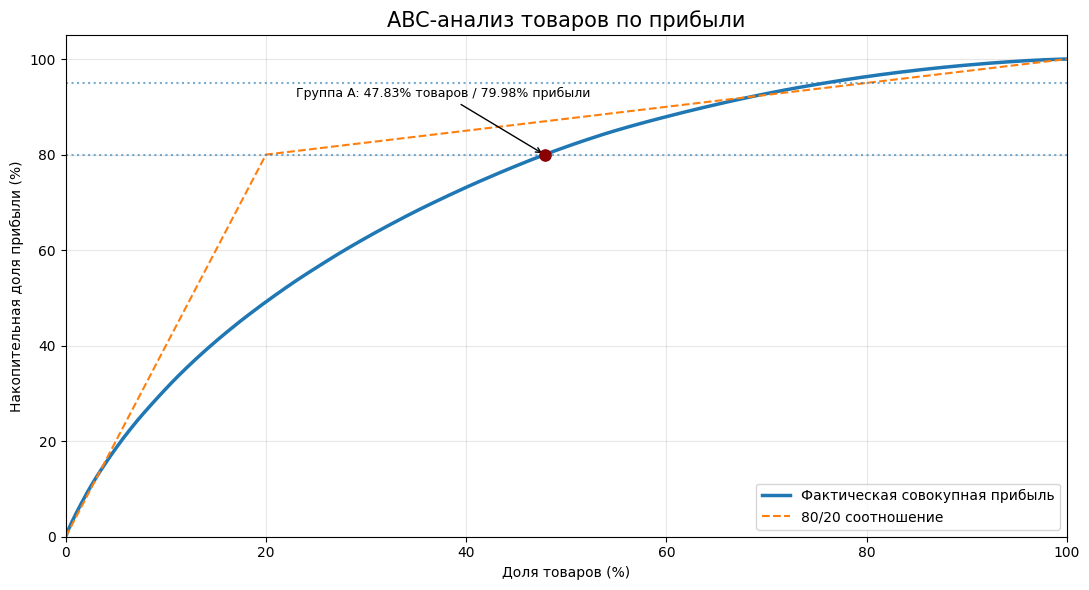

In [76]:
import matplotlib.pyplot as plt

plt.figure(figsize=(11, 6))

plt.plot(
    df_abc["cumulative_products_pct"],
    df_abc["cumulative_profit_pct"],
    linewidth=2.5,
    label="Фактическая совокупная прибыль"
)

# Линия классического принципа Парето
plt.plot(
    [0, 20, 100],
    [0, 80, 100],
    linestyle="--",
    linewidth=1.5,
    label="80/20 соотношение"
)

# Границы групп ABC
plt.axhline(80, linestyle=":", alpha=0.6)
plt.axhline(95, linestyle=":", alpha=0.6)

plt.title("ABC-анализ товаров по прибыли", fontsize=15)
plt.xlabel("Доля товаров (%)")
plt.ylabel("Накопительная доля прибыли (%)")

plt.xlim(0, 100)
plt.ylim(0, 105)

plt.scatter(
    47.83, 79.98,
    color="darkred",
    s=65,
    zorder=5
)

plt.annotate(
    "Группа A: 47.83% товаров / 79.98% прибыли",
    xy=(47.83, 79.98),
    xytext=(23, 92),
    arrowprops={"arrowstyle": "->"},
    fontsize=9
)

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "images/abc_analysis.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Вывод: ABC-анализ товаров

ABC-анализ позволил разделить товары на три группы в зависимости от их вклада в общую прибыль.

**Результаты анализа:**

- **Группа A:** 562 товара (47,83% ассортимента) формируют 79,98% прибыли.
- **Группа B:** 329 товаров (28,00% ассортимента) формируют 15,01% прибыли.
- **Группа C:** 284 товара (24,17% ассортимента) формируют 5,02% прибыли.

**Основной вывод**

Классическое правило Парето 80/20 в исследуемых данных не подтверждается: для формирования примерно 80% прибыли требуется почти 48% ассортимента.

Это означает, что прибыль распределена между товарами относительно равномернее, чем предполагает правило 80/20.

**Бизнес-интерпретация:** компании важно управлять не только наиболее прибыльными товарами группы A, но и оценивать потенциал остальных групп.

**Рекомендации:**
- **Группа A:** поддерживать наличие товаров и контролировать риск дефицита.
- **Группа B:** изучить возможности увеличения продаж и прибыли.
- **Группа C:** проанализировать оборачиваемость, спрос и затраты на хранение. Не исключать товары из ассортимента только из-за принадлежности к группе C.

**Ограничения:** ABC-анализ выполнен по прибыли в USD за весь период 2021–2025 годов. Он не учитывает динамику спроса, сезонность отдельных товаров и затраты на хранение. Финансовые показатели требуют сверки с учётом выявленных расхождений в исходных данных.

## Итоговые результаты исследования

### Цель проекта

Проанализировать продажи интернет-магазина за 2021–2025 годы, изучить поведение покупателей, определить наиболее прибыльные товарные категории и выявить возможности улучшения бизнес-показателей.

### 1. Проверка гипотез

| Гипотеза | Результат |
|---|---|
| Количество заказов ежегодно растёт | Не подтвердилась: устойчивого роста нет |
| Продажи имеют сезонность | Подтвердилась: наблюдаются повторяющиеся пики в ноябре и декабре |
| Средний чек увеличивается | Не подтвердилась: AOV снизился примерно на 1,51% |
| Большинство клиентов совершает повторные покупки | Подтвердилась: Repeat Purchase Rate составляет 97,90% |
| Небольшая доля товаров формирует основную прибыль по правилу 80/20 | Не подтвердилась: 47,83% товаров формируют около 80% прибыли |

### 2. Ключевые результаты

**Продажи:** количество заказов остаётся относительно стабильным. Выручка в USD за период снизилась примерно на 1,06%.

**Клиенты:** большинство покупателей совершили более одного заказа за пять лет. Однако когортный анализ показал, что ежемесячная возвращаемость значительно ниже общего Repeat Purchase Rate.

**Товарные категории:** Electronics, Jewelry и Home Appliances формируют около 41,65% прибыли в анализируемой выборке USD.

**Ассортимент:** прибыль распределена между товарами относительно равномернее, чем предполагает классическое правило Парето 80/20.

**Качество данных:** у 11 236 заказов (8,14%) обнаружены расхождения между суммой заказа и суммой его товарных позиций.

### 3. Рекомендации для бизнеса

1. **Учитывать сезонность.** Планировать запасы, рекламные кампании и нагрузку на персонал с учётом повышенного спроса в ноябре и декабре.
2. **Изучить снижение среднего чека.** Проверить изменения товарной корзины, цен и количества товаров в заказе.
3. **Работать над частотой повторных покупок.** Исследовать интервалы между заказами и протестировать механики возвращения клиентов.
4. **Управлять ассортиментом на основе прибыли.** Поддерживать доступность товаров группы A, изучать потенциал группы B и анализировать эффективность группы C.
5. **Повысить качество финансовых данных.** Выяснить причины расхождений между заказами и товарными позициями до использования результатов для финансовых решений.

### 4. Ограничения исследования

- Данные охватывают период 2021–2025 годов.
- Денежные показатели анализировались только для заказов в USD, без конвертации остальных валют.
- Финансовые выводы предварительные из-за обнаруженных расхождений в исходных данных.
- Repeat Purchase Rate рассчитан за весь период наблюдения и не равен ежемесячному удержанию.
- Причины выявленных закономерностей требуют дополнительного исследования; результаты описывают связи и динамику, но не доказывают причинно-следственные зависимости.

### 5. Итог

Исследование показало, что интернет-магазин имеет стабильный объём заказов и выраженную сезонность, однако устойчивого роста выручки и среднего чека не наблюдается.

Основные направления дальнейшей работы — увеличение частоты покупок, оптимизация ассортимента и повышение достоверности финансовой отчётности.